# Phase 2: EDA and First Analytics
Loads the processed data built by `src/pipeline.py`. All cleaning logic lives in `src/`; this notebook only explores and interprets.

In [1]:
import sys; sys.path.insert(0, '../src')
import pandas as pd
import analytics as an
df = an.load()
print(df.shape)
df.head()

(6965247, 29)


,FlightDate,Year,Month,DayOfWeek,Reporting_Airline,Origin,Dest,route,dep_hour,season,...,cause_unreported,origin_hour_flights,dest_hour_flights,origin_day_flights,arr_outlier_iqr,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,2024-01-28,2024,1,7,G4,FLL,CVG,FLL-CVG,17,winter,...,0,17,7,304,1,346.0,0.0,0.0,0.0,0.0
1,2024-01-01,2024,1,1,G4,AVL,FLL,AVL-FLL,12,winter,...,0,3,13,24,0,0.0,0.0,0.0,0.0,0.0
2,2024-01-01,2024,1,1,G4,FLL,AVL,FLL-AVL,15,winter,...,0,17,1,280,0,0.0,0.0,0.0,0.0,0.0
3,2024-01-01,2024,1,1,G4,AVL,PIE,AVL-PIE,18,winter,...,0,2,2,24,0,0.0,26.0,0.0,0.0,0.0
4,2024-01-01,2024,1,1,G4,PIE,AVL,PIE-AVL,20,winter,...,0,2,3,21,0,0.0,0.0,0.0,0.0,0.0


## 1.Delay distribution and re-expression
Most flights arrive early, with the peak about 5 to 15 minutes before schedule, and the long tail sits on the late side (the bar at 300 is every flight 300+ minutes late, clipped into one bar). After the log re-expression, the late flights show up as a smaller bump of their own, which suggests delayed flights may behave differently from on-time ones.

- Drawn from a random sample of 300,000 flights (fixed seed).

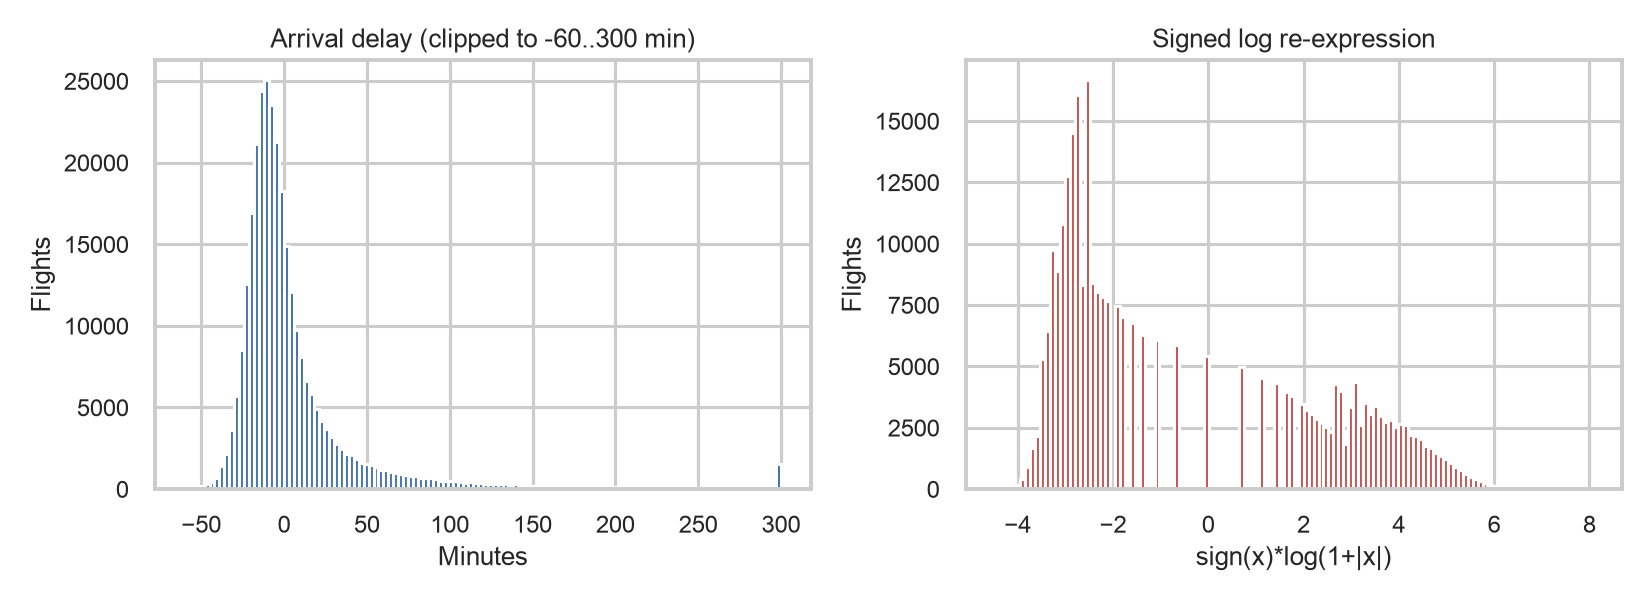

In [2]:
an.fig_delay_distribution(df)
from IPython.display import Image; Image('../figures/01_delay_distribution.png')

## 2. Categorical: Carrier boxplot
Almost every carrier has a median arrival slightly early (roughly -11 to -1 minutes), so the typical flight isn't late for anyone. The real differences are in the upper quartile and whiskers, where F9, AA and B6 spread much further into late arrivals than HA, 9E or YX.

- Drawn from a random sample of 300,000 flights (fixed seed).

,flights,delay15_rate,median_arr_delay,iqr_arr_delay
Reporting_Airline,,,,
F9,203482,0.287401,-4.0,36.0
AA,966116,0.261340,-4.0,31.0
B6,235683,0.255093,-6.0,33.0
NK,255633,0.239261,-6.0,30.0
AS,240323,0.220720,-4.0,26.0
OH,223673,0.217702,-6.0,26.0
G4,114882,0.216718,-8.0,28.0
MQ,275317,0.208603,-6.0,24.0
WN,1404597,0.206048,-5.0,23.0


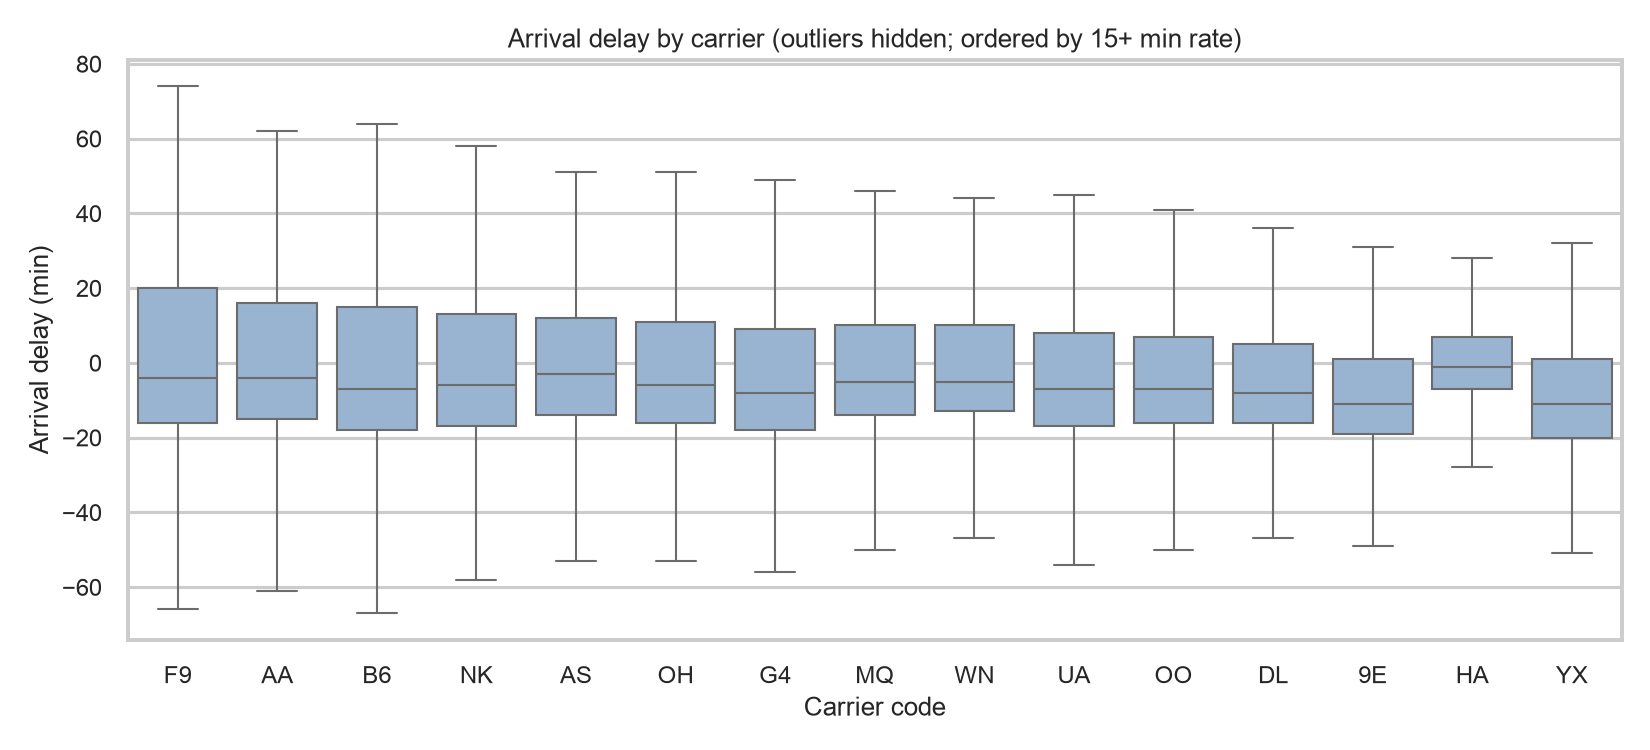

In [3]:
display(an.table_carrier_summary(df))
an.fig_carrier_box(df); Image('../figures/02_carrier_boxplot.png')

## 3. Bivariate: departure vs arrival delay
Most flights cluster near zero departure delay and land about 10 minutes early, and from there arrival delay rises roughly one-for-one with departure delay. So a late departure mostly stays late at the destination, and the pile-up in the top right corner is just the clipping at 240 and 300.

- Drawn from a random sample of 300,000 flights (fixed seed).

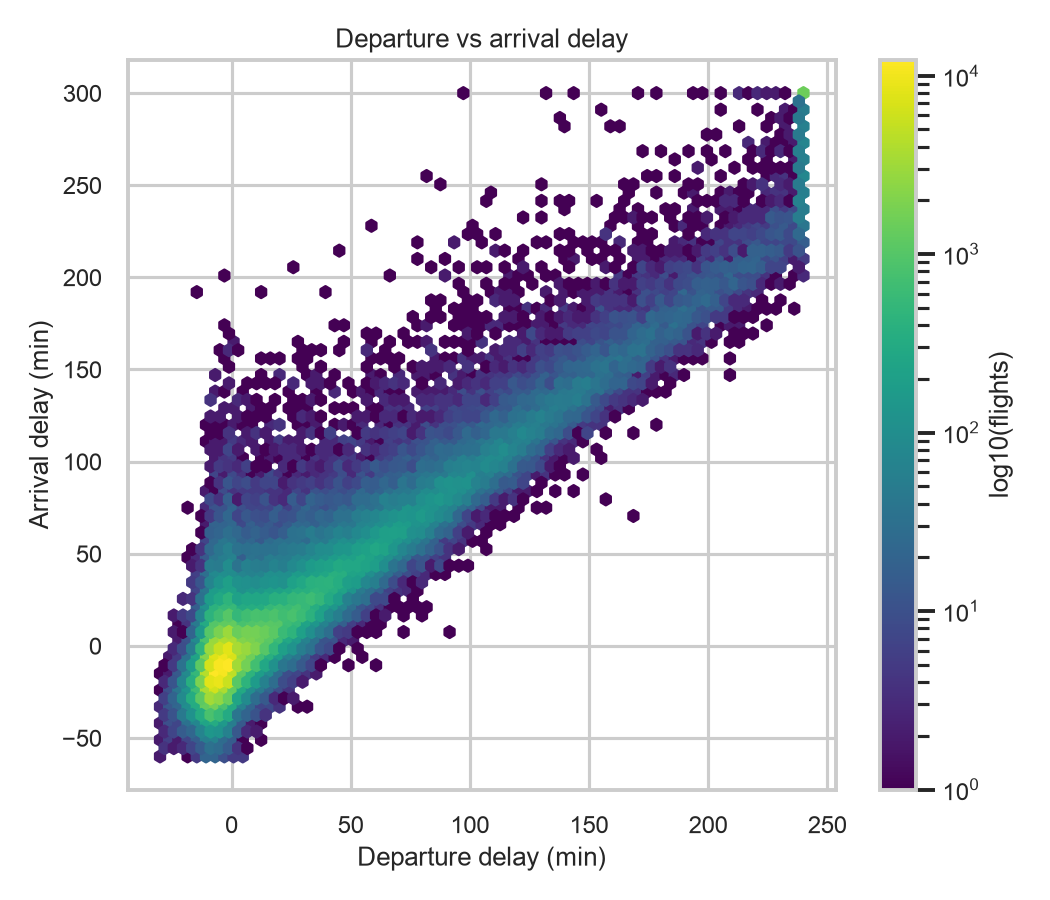

In [4]:
an.fig_dep_vs_arr_hexbin(df); Image('../figures/03_dep_vs_arr_hexbin.png')

## 4. Cascade: inherited delay with resistant fit and residuals (Research Question, cascade part)
The median departure delay follows the resistant line closely, and the Theil-Sen slope of 0.93 means about 93% of an inbound delay shows up again on the next departure. The residuals are flat for most of the range, but early inbound legs don't lead to early departures, and the last bin at 240 drops by about 28 minutes where the data is thin.

- Computed on all 6,965,247 flights.

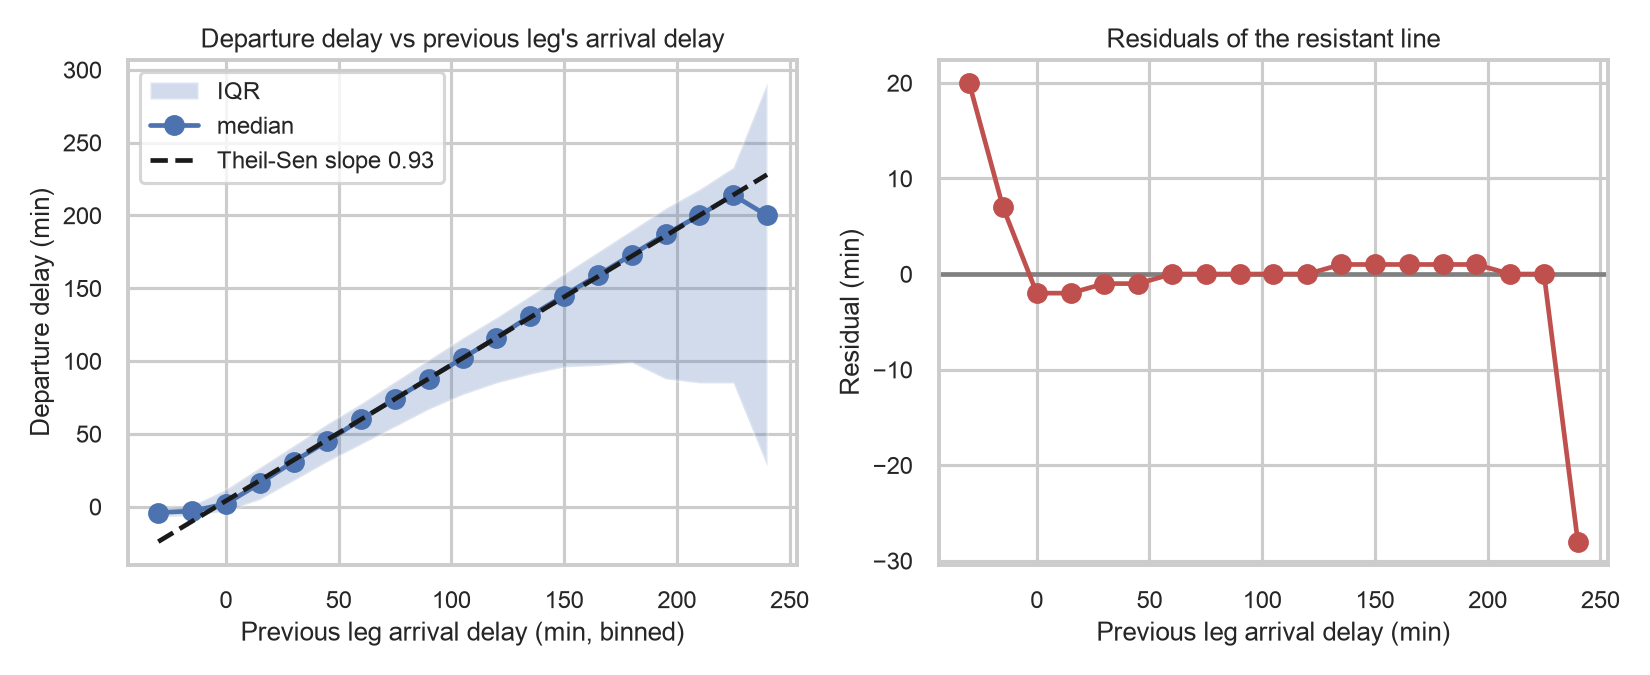

In [5]:
an.fig_inherited_delay_with_residuals(df); Image('../figures/04_inherited_delay_residuals.png')

## 5. Delay by hour at hubs
Median departure delay at the busiest airports stays slightly early through the morning, then creeps up in the afternoon and evening, DFW reaches about 13 minutes late at hour 23 and ORD about 12 at hour 22. DEN and CLT peak around 6 to 7. The CLT spike rests on 80 flights at hour 0 and only 2 at hour 1, so you're not reading anything into it. This also explains the gaps at hours 2 to 4 in Fig 5, where the airports have too few flights to plot.
- Computed on all 6,965,247 flights.

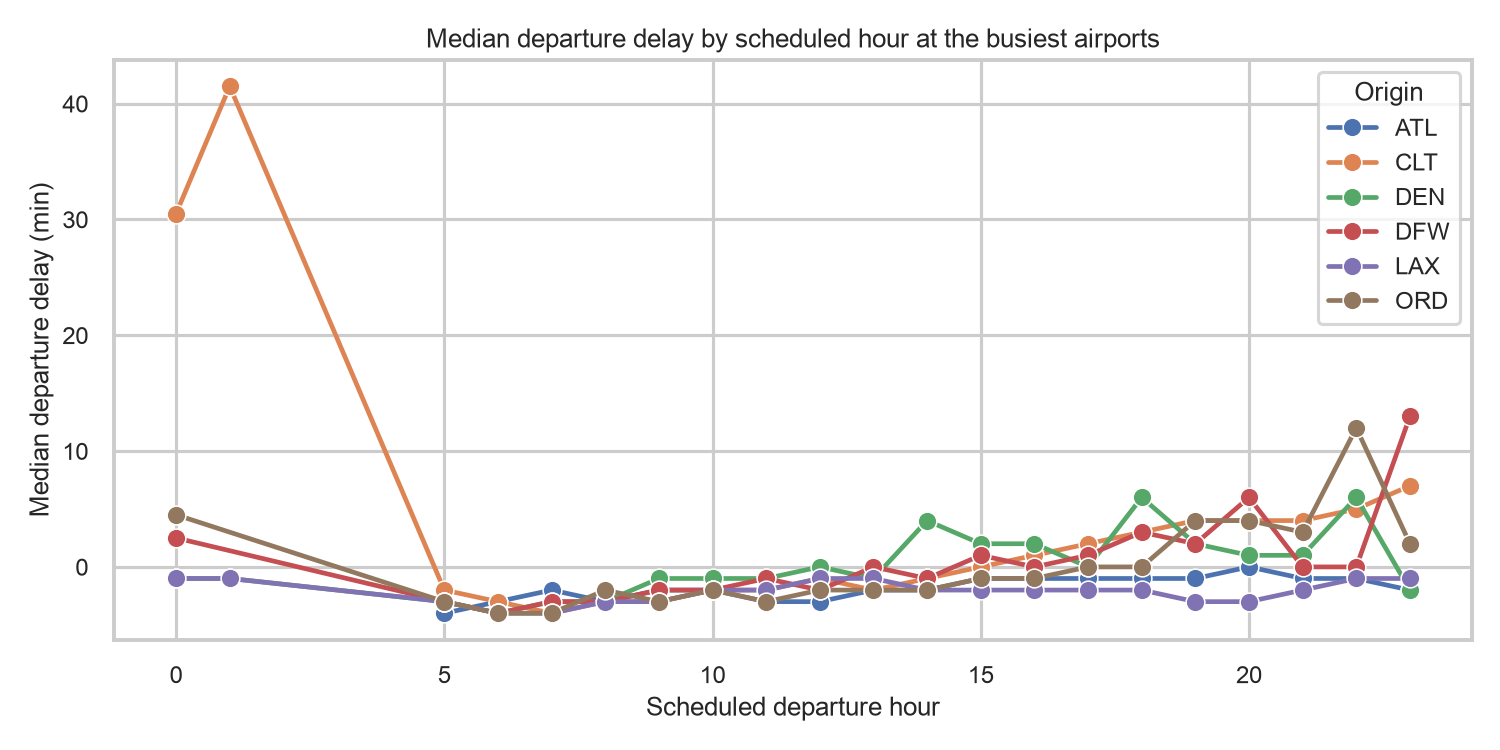

In [6]:
an.fig_delay_by_hour_hubs(df); Image('../figures/05_delay_by_hour_hubs.png')

## 6. Cause shares
Late aircraft delay is the largest or near-largest slice in most months, at about 4 in 10 delay minutes, with carrier delay close behind at roughly a third. Weather is at most about 10% and security is barely visible, and the mix stays fairly similar across months, so it doesn't point to one cause for the January and July spikes.

- Computed on all 6,965,247 flights.

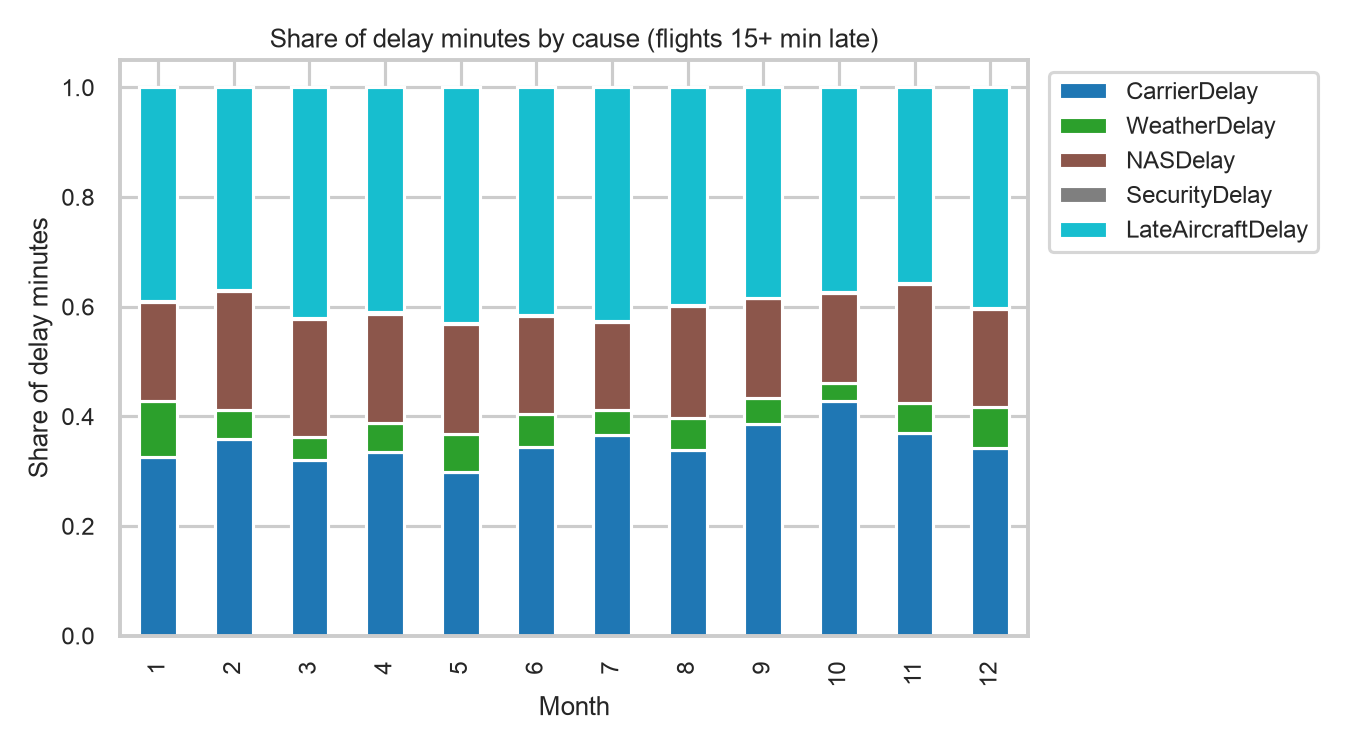

In [7]:
an.fig_cause_shares(df); Image('../figures/06_cause_shares.png')

## 7. Daily trend
The 7-day rolling mean shows the share of 15+ minute arrival delays peaking in mid-January (about 0.37), mid-July (about 0.42) and late December, and falling to about 0.1 to 0.15 in September to November. Those spikes are much bigger than normal day-to-day noise, so they're real events I still need to explain.

- Computed on all 6,965,247 flights.

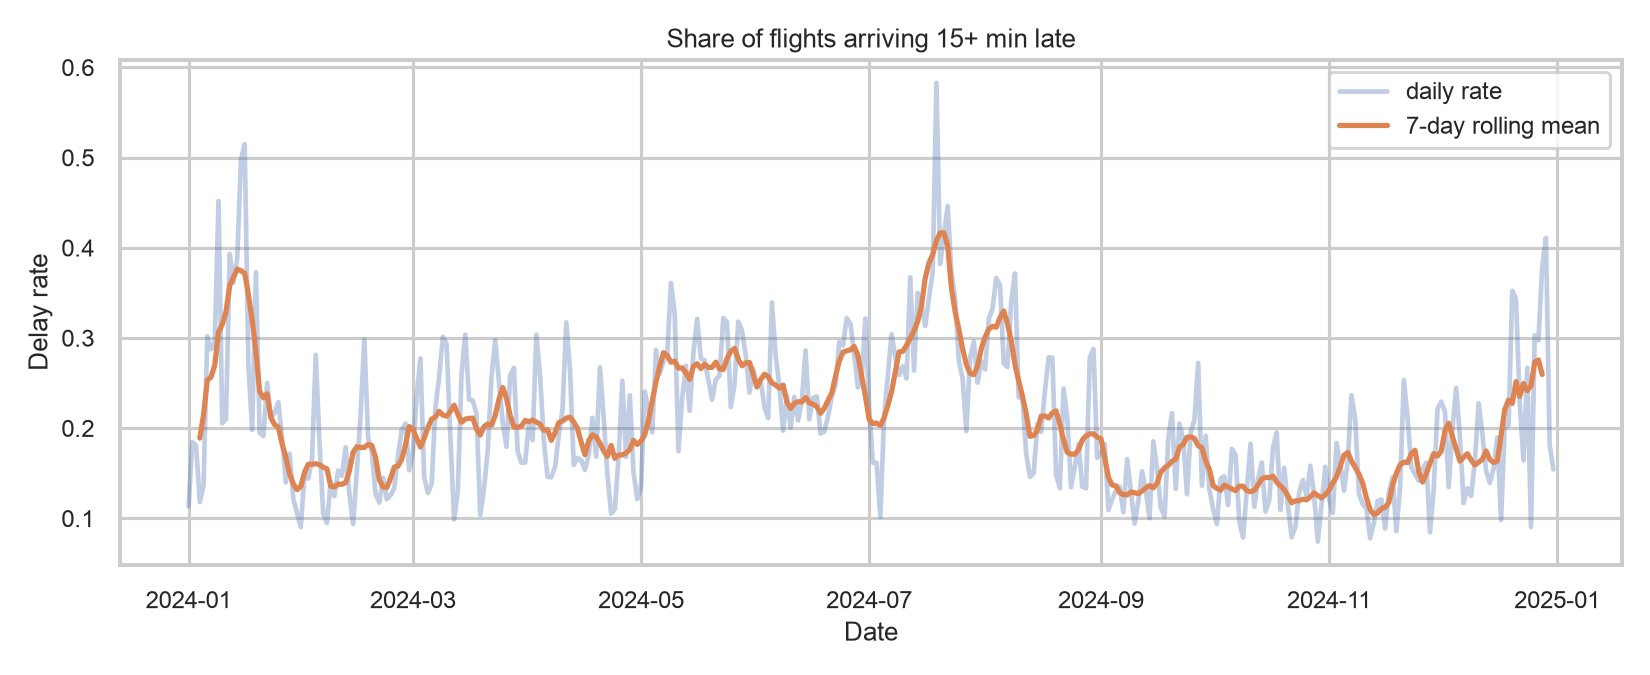

In [8]:
an.fig_daily_trend(df); Image('../figures/07_daily_trend.png')

## 8. Missingness patterns
Previous-leg delay is missing for nearly every first leg of the day and for only about 1 to 2% of later legs, so the missingness is structural, not random. By carrier it ranges from about 19% (OH) to 33% (UA), probably because airlines differ in how many first-of-day flights they run, so filling in a value would be misleading.

- Computed on all 6,965,247 flights.

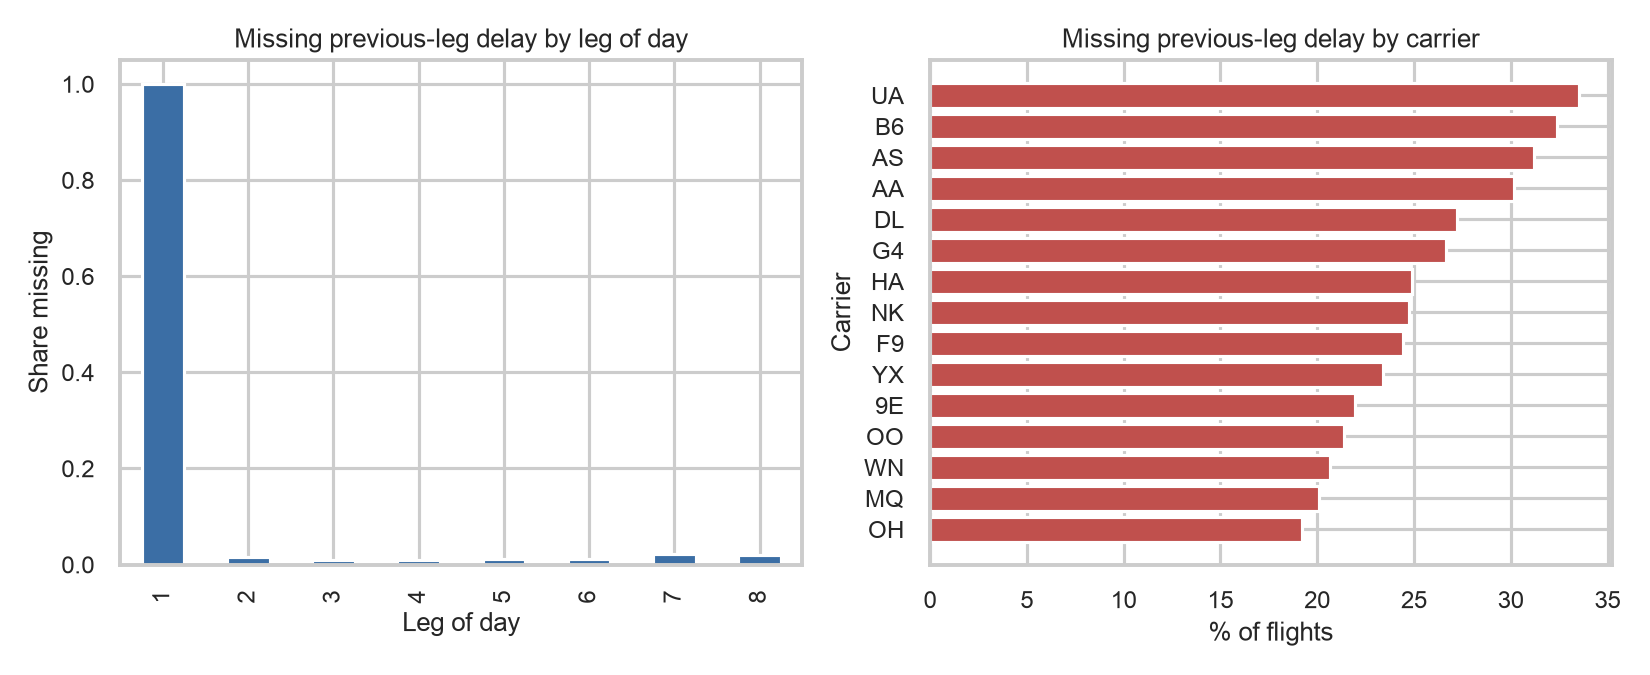

In [9]:
an.fig_missingness(df); Image('../figures/08_missingness.png')

## 9. Chronically worst airports
ASE has the highest share of 15+ minute departure delays at about 30%, followed by BWI, DFW and a group of Florida airports (FLL, MIA, MCO, EYW, PBI), and even the 15th airport is still near 23%. The list mixes big hubs with smaller or seasonal airports, so airport size alone doesn't explain delays.

- Computed on all 6,965,247 flights.


,flights,dep_delay15,median_dep_delay
Origin,,,
ASE,7307,0.302860,-3.0
BWI,97251,0.285354,2.0
DFW,306872,0.274574,-1.0
FLL,90121,0.271424,0.0
MIA,107722,0.270632,-1.0
CLT,214077,0.264003,-1.0
DAL,71740,0.254168,1.0
EYW,7659,0.250294,-3.0
MCO,156258,0.245184,-1.0


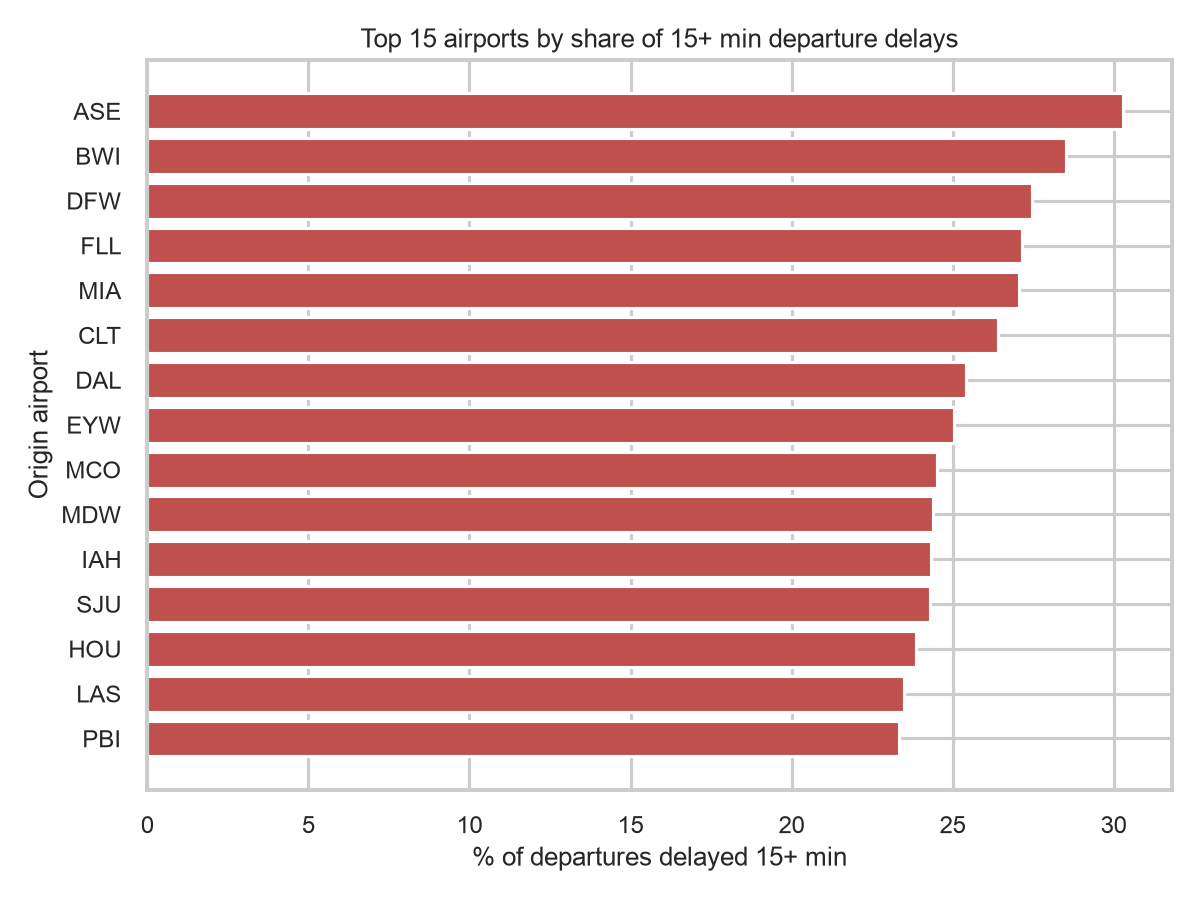

In [10]:
display(an.table_worst_airports(df).head(15))
an.fig_worst_airports(df); Image('../figures/09_worst_airports.png')

## 10. Seasonality
Median arrival delay is slightly early in every season (roughly -9 to -4 minutes), so the middle of the distribution barely changes. The difference is in the upper quartile, where summer's sits around 15 minutes late compared with about 3 in fall, so summer has the heavier late side.

- Drawn from a random sample of 150,000 flights (fixed seed).

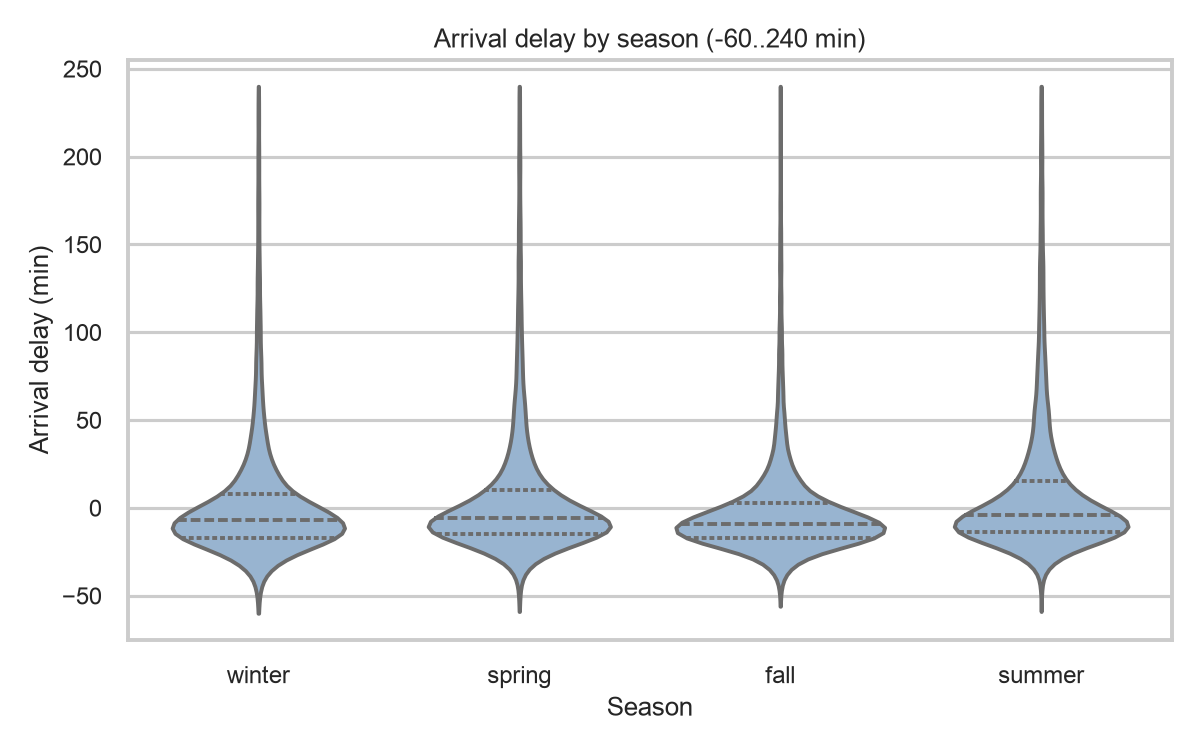

In [11]:
an.fig_season_violin(df); Image('../figures/10_season_violin.png')

## 11. Congestion (a pre-departure feature from our Phase 1 plan)
The share of 15+ minute departure delays rises from about 18% at the quietest hours to about 24% near 55 scheduled flights, but the line is bumpy and drops again at the busiest bins. The median only moves from -4 to -1 minutes, so congestion on its own is a weak signal and I'll treat it as one feature among several in Phase 3.

- Computed on all 6,965,247 flights.


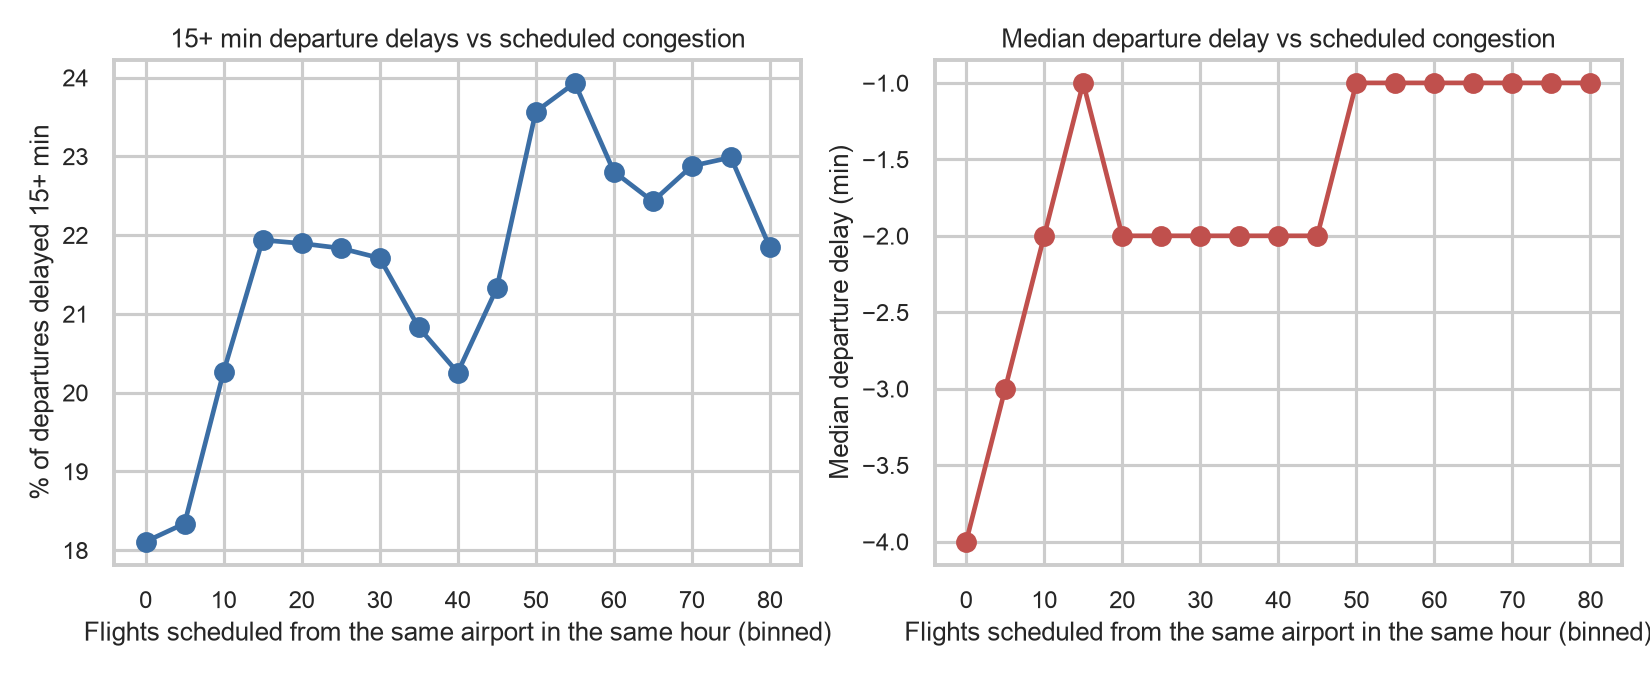

In [12]:
an.fig_congestion(df); Image('../figures/11_congestion.png')

## 12. Weekday and hour heatmap
Delay chance climbs through the day, from under 10% around 5 to 7 a.m. to about 35% at 8 p.m. on Thursday, Friday and Sunday, so schedule timing alone moves the risk about fivefold. The bright cells between 0 and 4 a.m. likely come from very few flights, so you won't over-read them.

- Computed on all 6,965,247 flights.

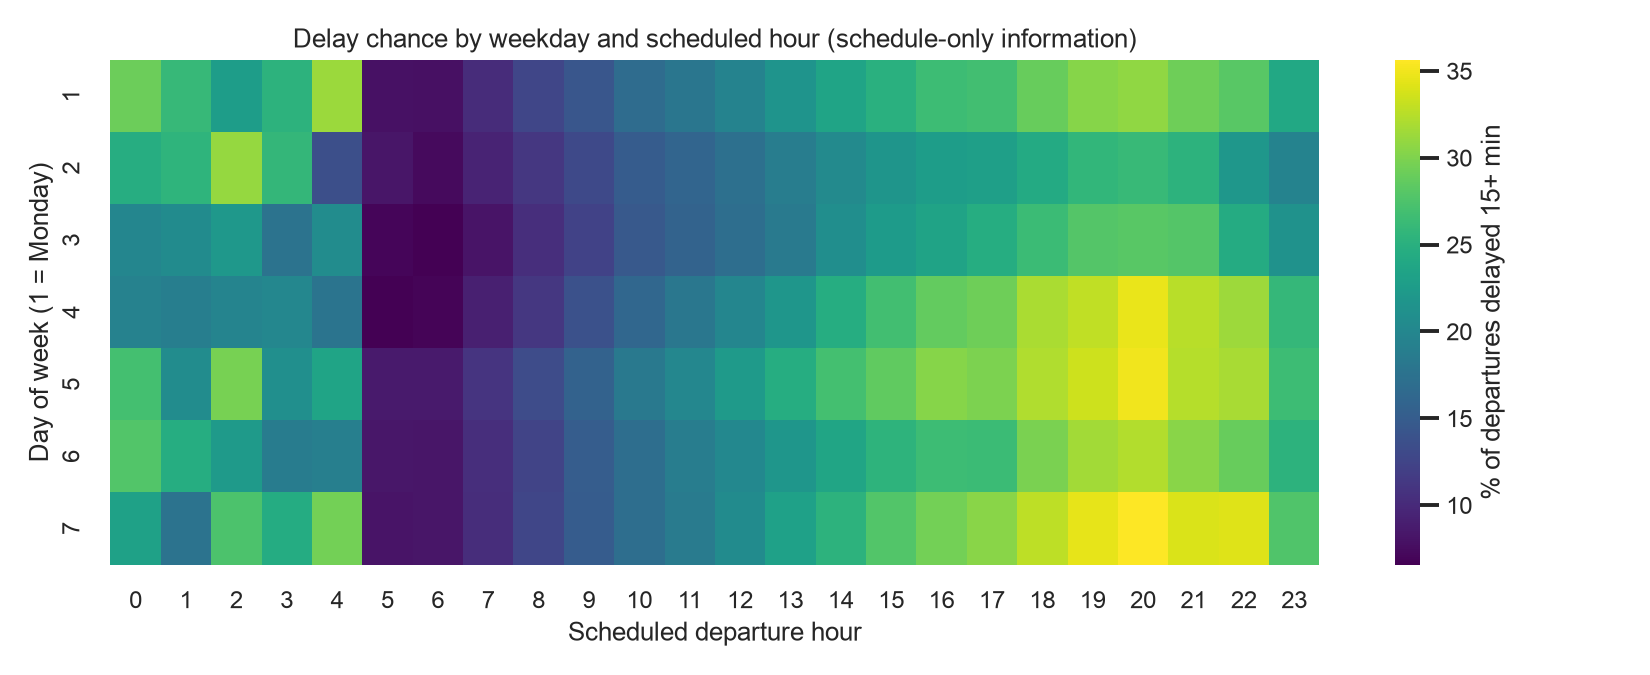

In [13]:
an.fig_advance_heatmap(df); Image('../figures/12_weekday_hour_heatmap.png')